# t-SNE — Visualizing Local Neighborhood Structure

## 1. Definition and intuition
t-SNE (t-distributed Stochastic Neighbor Embedding) maps high-dimensional data to a low-dimensional space by trying to preserve local-neighbor probabilities. Nearby pairs in the original space should usually remain nearby in the embedding. Global distances, cluster sizes and density are not reliably preserved.

## 2. Probability construction
High-dimensional conditional affinities are Gaussian:
$$
p_{j|i}=\frac{\exp(-\|x_i-x_j\|^2/(2\sigma_i^2))}
{\sum_{k\ne i}\exp(-\|x_i-x_k\|^2/(2\sigma_i^2))}.
$$
Each $\sigma_i$ is chosen by binary search to target a perplexity, roughly an effective neighborhood size. Symmetrize to $p_{ij}=(p_{j|i}+p_{i|j})/(2n)$.

In the low-dimensional map, use Student-t affinities $q_{ij}\propto(1+\|y_i-y_j\|^2)^{-1}$ and minimize $KL(P\|Q)=\sum_{ij}p_{ij}\log(p_{ij}/q_{ij})$.

## 3. Why it works and limitations
The objective penalizes pairs that are close in the high-dimensional similarity distribution but far apart in the map. The heavy-tailed low-dimensional distribution helps alleviate the crowding problem. Optimization is non-convex and depends on initialization, perplexity, learning rate, and iterations. Distances between separated clusters should not be read as calibrated global distances.

In [1]:
import time
import inspect
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler

SEED = 42
digits = load_digits()
# A stratified subsample keeps the from-scratch educational implementation manageable.
X_all, y_all = digits.data, digits.target
_, X_small, _, y_small = train_test_split(
    X_all, y_all, test_size=0.14, stratify=y_all, random_state=SEED
)
X_small = StandardScaler().fit_transform(X_small)
print("t-SNE demo subset:", X_small.shape)


t-SNE demo subset: (252, 64)


## 4. From-scratch t-SNE (small data, educational)

This implementation includes per-point bandwidth search, probability symmetrization, Student-t affinities, and gradient descent with momentum. It is intended to expose the objective's mechanics, not to replace optimized Barnes–Hut or FFT-based implementations.

In [2]:
def pairwise_sq_dists(X):
    sq = np.sum(X*X, axis=1)
    return np.maximum(sq[:,None] + sq[None,:] - 2*X@X.T, 0.0)

def joint_probabilities_tsne(X, perplexity=20.0, tol=1e-5, max_search=50):
    X = np.asarray(X, dtype=float)
    n = len(X)
    if X.ndim != 2 or n < 3 or not 1 <= perplexity < n:
        raise ValueError("Invalid X or perplexity")
    D2 = pairwise_sq_dists(X)
    P_cond = np.zeros((n,n))
    target = np.log(perplexity)
    for i in range(n):
        beta, lo, hi = 1.0, -np.inf, np.inf
        mask = np.arange(n) != i
        Di = D2[i, mask]
        for _ in range(max_search):
            vals = np.exp(-Di*beta)
            total = vals.sum() + 1e-12
            probs = vals / total
            entropy = np.log(total) + beta*np.sum(Di*probs)
            diff = entropy - target
            if abs(diff) < tol:
                break
            if diff > 0:
                lo = beta
                beta = beta*2 if np.isinf(hi) else (beta+hi)/2
            else:
                hi = beta
                beta = beta/2 if np.isinf(lo) else (beta+lo)/2
        P_cond[i, mask] = probs
    P = (P_cond + P_cond.T) / (2*n)
    P = np.maximum(P, 1e-12)
    np.fill_diagonal(P, 0)
    P /= P.sum()
    return P

def tsne_scratch(X, n_components=2, perplexity=20, n_iter=400, learning_rate=100, early_exaggeration=4, random_state=42):
    X = np.asarray(X, dtype=float)
    if n_iter < 1 or learning_rate <= 0:
        raise ValueError("Invalid optimization hyperparameters")
    P = joint_probabilities_tsne(X, perplexity=perplexity)
    rng = np.random.default_rng(random_state)
    Y = rng.normal(scale=1e-4, size=(len(X), n_components))
    velocity = np.zeros_like(Y)
    gains = np.ones_like(Y)
    history = []
    for it in range(n_iter):
        sum_y = np.sum(Y*Y, axis=1)
        d2 = np.maximum(sum_y[:,None]+sum_y[None,:]-2*Y@Y.T, 0)
        num = 1/(1+d2)
        np.fill_diagonal(num, 0)
        Q = num / (num.sum()+1e-12)
        exaggeration = early_exaggeration if it < min(100, n_iter//3) else 1.0
        P_use = P * exaggeration
        diff = (P_use - Q) * num
        grad = 4*(np.diag(diff.sum(axis=1)) @ Y - diff @ Y)
        momentum = 0.5 if it < 100 else 0.8
        gains = np.where(np.sign(grad) != np.sign(velocity), gains + 0.2, gains*0.8)
        gains = np.maximum(gains, 0.01)
        velocity = momentum*velocity - learning_rate*gains*grad
        Y += velocity
        Y -= Y.mean(axis=0, keepdims=True)
        if it % 50 == 0 or it == n_iter-1:
            Qsafe = np.maximum(Q, 1e-12)
            history.append(float(np.sum(P*np.log(np.maximum(P,1e-12)/Qsafe))))
    return Y, history, P

# Use a smaller subset for the explicit optimizer so this lesson runs quickly.
X_ts = X_small[:180]
y_ts = y_small[:180]
Y_scratch, kl_history, P = tsne_scratch(X_ts, perplexity=20, n_iter=300, learning_rate=80, random_state=SEED)
print("Scratch embedding:", Y_scratch.shape, "KL checkpoints:", np.round(kl_history[-3:], 3))


Scratch embedding: (180, 2) KL checkpoints: [0.374 0.372 0.371]


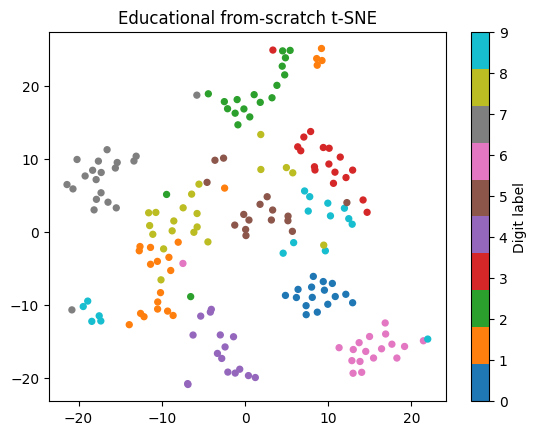

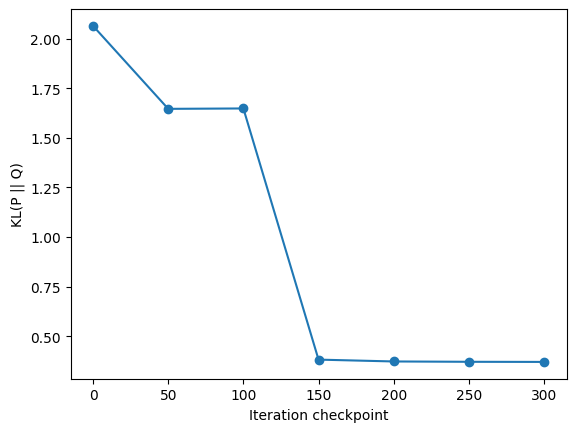

In [3]:
plt.scatter(Y_scratch[:,0], Y_scratch[:,1], c=y_ts, cmap="tab10", s=18)
plt.title("Educational from-scratch t-SNE"); plt.colorbar(label="Digit label"); plt.show()
plt.plot(np.arange(len(kl_history))*50, kl_history, marker="o")
plt.xlabel("Iteration checkpoint"); plt.ylabel("KL(P || Q)"); plt.show()


## 5. Compare with scikit-learn

The results need not match because random starts and optimization details differ. t-SNE embeddings are stochastic and should be used primarily for exploratory visualization.

sklearn embedding: (180, 2) finite: True


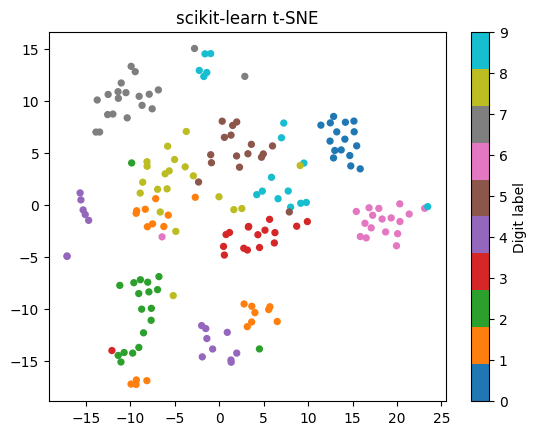

In [4]:
params = dict(n_components=2, perplexity=20, init="pca", learning_rate="auto", random_state=SEED)
if "max_iter" in inspect.signature(TSNE).parameters:
    params["max_iter"] = 500
else:
    params["n_iter"] = 500
Y_sk = TSNE(**params).fit_transform(X_ts)
print("sklearn embedding:", Y_sk.shape, "finite:", np.isfinite(Y_sk).all())
plt.scatter(Y_sk[:,0], Y_sk[:,1], c=y_ts, cmap="tab10", s=18)
plt.title("scikit-learn t-SNE"); plt.colorbar(label="Digit label"); plt.show()
assert Y_sk.shape == Y_scratch.shape and np.isfinite(Y_sk).all()


## 6. Hyperparameters, complexity and scaling
- `perplexity`: effective neighborhood scale; often compare several values. Must be less than sample count.
- `learning_rate`, iterations, initialization, early exaggeration and random seed affect the map.
- Exact pairwise t-SNE is $O(n^2)$ in memory and per iteration. Barnes–Hut commonly reduces practical work toward $O(n\log n)$ for low-dimensional embeddings; FFT-based methods use a different approximation.
- Use PCA or Truncated SVD first when input dimension is very high; subsample for visualization. Do not treat cluster sizes or between-cluster distances as quantitative.
- GPU variants exist (for example, in specialized libraries), but standard scikit-learn t-SNE is CPU-based and optimized approximations are important at scale.

## 7. Correctness tests and synthesis
t-SNE emphasizes local probability structure through a non-convex KL-divergence objective. It is a visualization technique, not a general-purpose feature extractor with a stable out-of-sample transform in the standard scikit-learn implementation.

In [5]:
assert np.allclose(P.sum(), 1.0, atol=1e-7)
assert np.allclose(P, P.T, atol=1e-10)
assert np.allclose(np.diag(P), 0)
assert np.isfinite(Y_scratch).all() and np.isfinite(kl_history).all()
print("All t-SNE checks passed.")


All t-SNE checks passed.
